In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## Data Understanding 

In [27]:
# Import data
delivery_data = pd.read_csv("../data/olist_delivery_time_data.csv")
delivery_data.head()

,order_id,purchase_dayofweek,purchase_month,purchase_hour,purchase_is_weekend,estimated_delivery_days,n_items,n_sellers,total_price,total_freight,...,product_width_cm,payment_installments,payment_value,payment_type,customer_state,seller_state,product_category_name_english,distance_km,same_state,delivery_time_days
0,e481f51cbdc54678b7cc49136f2d6af7,0,10,10,0,15.544063,1,1,29.99,8.72,...,13.0,1.0,38.71,voucher,SP,SP,housewares,18.681711,1,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,1,7,20,0,19.137766,1,1,118.70,22.76,...,19.0,1.0,141.46,boleto,BA,SP,perfumery,861.035367,0,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,2,8,8,0,26.639711,1,1,159.90,19.22,...,21.0,3.0,179.12,credit_card,GO,SP,auto,514.547140,0,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,5,11,19,1,26.188819,1,1,45.00,27.20,...,20.0,1.0,72.20,credit_card,RN,MG,pet_shop,1821.802656,0,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,1,2,21,0,12.112049,1,1,19.90,8.72,...,15.0,1.0,28.62,credit_card,SP,SP,stationery,29.593095,1,2.873877


In [28]:
print(f"The data has {delivery_data.shape[0]} rows and {delivery_data.shape[1]} columns.")

The data has 96478 rows and 24 columns.


In [29]:
# Structural summary of data
delivery_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 96478 entries, 0 to 96477
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       96478 non-null  str    
 1   purchase_dayofweek             96478 non-null  int64  
 2   purchase_month                 96478 non-null  int64  
 3   purchase_hour                  96478 non-null  int64  
 4   purchase_is_weekend            96478 non-null  int64  
 5   estimated_delivery_days        96478 non-null  float64
 6   n_items                        96478 non-null  int64  
 7   n_sellers                      96478 non-null  int64  
 8   total_price                    96478 non-null  float64
 9   total_freight                  96478 non-null  float64
 10  avg_price                      96478 non-null  float64
 11  product_weight_g               96462 non-null  float64
 12  product_length_cm              96462 non-null  float64
 1

In [30]:
# Statistical summary of data
delivery_data.describe()

,purchase_dayofweek,purchase_month,purchase_hour,purchase_is_weekend,estimated_delivery_days,n_items,n_sellers,total_price,total_freight,avg_price,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_installments,payment_value,distance_km,same_state,delivery_time_days
count,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96462.000000,96462.000000,96462.000000,96462.000000,96477.000000,96477.000000,96000.000000,96478.000000,96470.000000
mean,2.756577,6.031116,14.773192,0.230001,23.736347,1.142198,1.013900,137.041586,22.785253,125.234076,2097.746968,30.093125,16.447803,23.013891,2.928024,159.856357,600.654736,0.359730,12.558217
std,1.967058,3.228391,5.328374,0.420835,8.760765,0.538804,0.123536,209.045198,21.559197,189.698083,3754.111279,16.097278,13.284786,11.723022,2.712723,218.813144,594.146033,0.479924,9.546156
min,0.000000,1.000000,0.000000,0.000000,2.008009,1.000000,1.000000,0.850000,0.000000,0.850000,0.000000,7.000000,2.000000,6.000000,0.000000,9.590000,0.000000,0.000000,0.533414
25%,1.000000,3.000000,11.000000,0.000000,18.330081,1.000000,1.000000,45.900000,13.850000,41.908333,300.000000,18.000000,8.000000,15.000000,1.000000,61.880000,184.972815,0.000000,6.766204
50%,3.000000,6.000000,15.000000,0.000000,23.230880,1.000000,1.000000,86.575000,17.170000,79.000000,700.000000,25.000000,13.000000,20.000000,2.000000,105.280000,433.773044,0.000000,10.217477
75%,4.000000,8.000000,19.000000,0.000000,28.407590,1.000000,1.000000,149.900000,24.017500,139.900000,1800.000000,38.000000,20.000000,30.000000,4.000000,176.330000,798.210166,1.000000,15.720182
max,6.000000,12.000000,23.000000,1.000000,155.135463,21.000000,5.000000,13440.000000,1794.960000,6735.000000,40425.000000,105.000000,105.000000,118.000000,24.000000,13664.080000,8677.859564,1.000000,209.628611


In [31]:
# Columns in data
print("Columns:", delivery_data.columns)

Columns: Index(['order_id', 'purchase_dayofweek', 'purchase_month', 'purchase_hour',
       'purchase_is_weekend', 'estimated_delivery_days', 'n_items',
       'n_sellers', 'total_price', 'total_freight', 'avg_price',
       'product_weight_g', 'product_length_cm', 'product_height_cm',
       'product_width_cm', 'payment_installments', 'payment_value',
       'payment_type', 'customer_state', 'seller_state',
       'product_category_name_english', 'distance_km', 'same_state',
       'delivery_time_days'],
      dtype='str')


In [32]:
# Datatypes in data
delivery_data.dtypes

order_id                             str
purchase_dayofweek                 int64
purchase_month                     int64
purchase_hour                      int64
purchase_is_weekend                int64
estimated_delivery_days          float64
n_items                            int64
n_sellers                          int64
total_price                      float64
total_freight                    float64
avg_price                        float64
product_weight_g                 float64
product_length_cm                float64
product_height_cm                float64
product_width_cm                 float64
payment_installments             float64
payment_value                    float64
payment_type                         str
customer_state                       str
seller_state                         str
product_category_name_english        str
distance_km                      float64
same_state                         int64
delivery_time_days               float64
dtype: object

In [33]:
# Missing values in data
delivery_data.isnull().sum()

order_id                            0
purchase_dayofweek                  0
purchase_month                      0
purchase_hour                       0
purchase_is_weekend                 0
estimated_delivery_days             0
n_items                             0
n_sellers                           0
total_price                         0
total_freight                       0
avg_price                           0
product_weight_g                   16
product_length_cm                  16
product_height_cm                  16
product_width_cm                   16
payment_installments                1
payment_value                       1
payment_type                        1
customer_state                      0
seller_state                        0
product_category_name_english    1378
distance_km                       478
same_state                          0
delivery_time_days                  8
dtype: int64

In [34]:
# Duplicate values in data
delivery_data.duplicated().sum()

np.int64(0)

In [35]:
delivery_data["delivery_time_days"].describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_time_days, dtype: float64

## Exploratory Data Analysis 

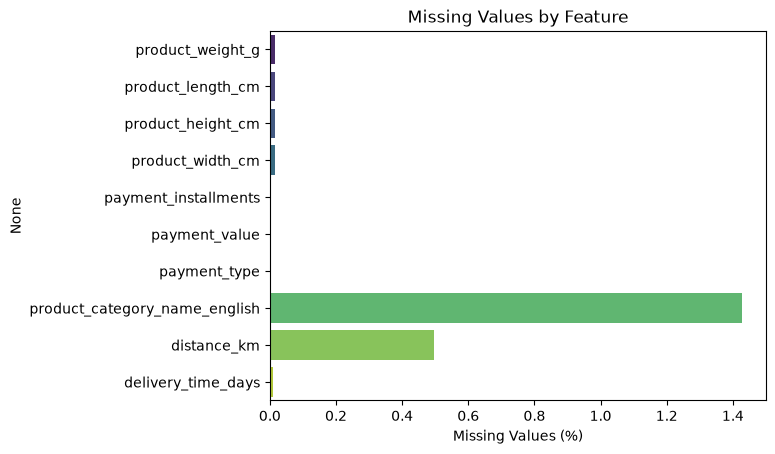

In [36]:
missing = delivery_data.isnull().mean() * 100
missing = missing[missing > 0]

sns.barplot(x=missing.values, y=missing.index, palette="viridis")
plt.title('Missing Values by Feature')
plt.xlabel('Missing Values (%)')
plt.savefig('../images/missing_value_distribution.png', bbox_inches='tight')
plt.show()

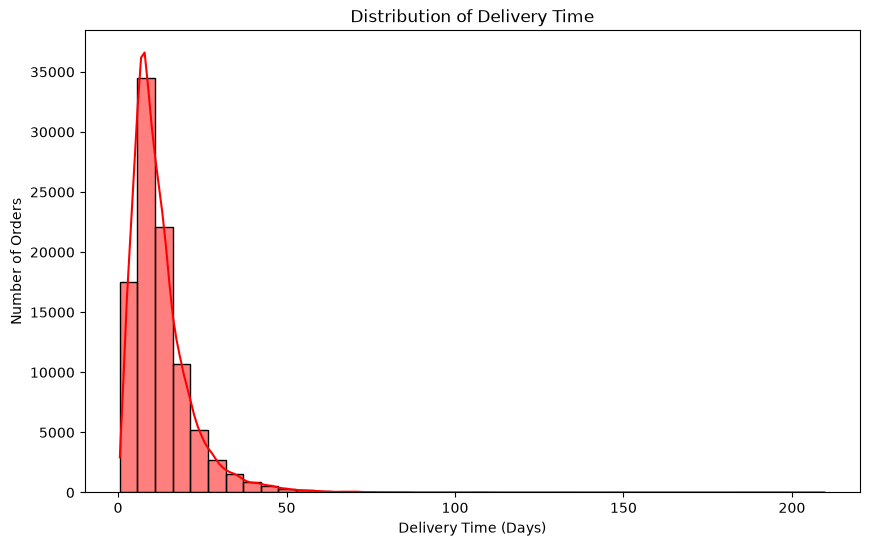

In [37]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=delivery_data,
    x='delivery_time_days',
    kde=True,
    bins=40,
    color="red"
)

plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (Days)')
plt.ylabel('Number of Orders')
plt.savefig('../images/delivery_time_distribution.png', bbox_inches='tight')
plt.show()

**The data is right skewed. Most orders arrive quickly, while a few extreme outliers take much longer. I will do log transformation in data cleaning**

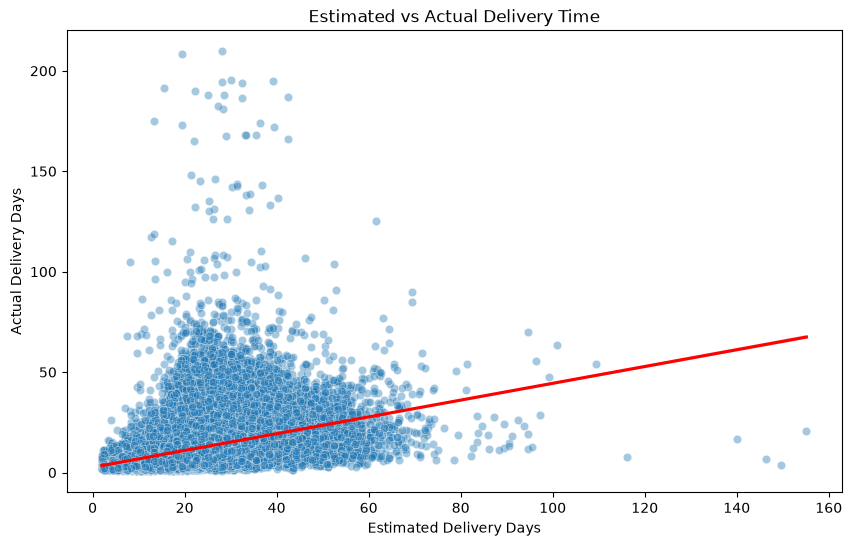

In [38]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=delivery_data,
    x='estimated_delivery_days',
    y='delivery_time_days',
    alpha=0.4
)

sns.regplot(
    data=delivery_data,
    x='estimated_delivery_days',
    y='delivery_time_days',
    scatter=False,
    color="red"
)

plt.title('Estimated vs Actual Delivery Time')
plt.xlabel('Estimated Delivery Days')
plt.ylabel('Actual Delivery Days')
plt.savefig('../images/estimated_vs_actual_delivery.png', bbox_inches='tight')
plt.show()

**The estimated delivery time does not match the actual delivery time. While the red trend line shows a positive relationship, the huge vertical spread indicates that real-world delivery times are highly unpredictable and take much longer than estimated.**

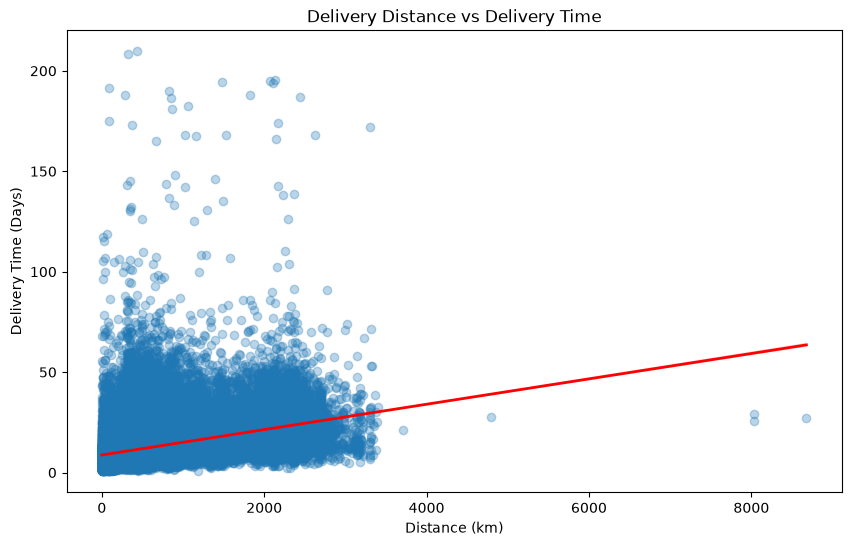

In [39]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=delivery_data,
    x='distance_km',
    y='delivery_time_days',
    scatter_kws={'alpha': 0.3},
    line_kws={'linewidth': 2, 'color': 'red'}
)

plt.title('Delivery Distance vs Delivery Time')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery Time (Days)')
plt.savefig('../images/delivery_time_vs_delivery_distance.png', bbox_inches='tight')
plt.show()

* **Yes, delivery distance affect delivery time. The upward trend line indicates a positive relationship: as the distance increases, the delivery time tends to increase.**
* **The wide vertical spread of the data points—especially at distances under 4,000 km—shows that many short-distance deliveries still take a very long time. this tells us that while distance is a factor, it is not the only variable determining how long a delivery will take.**

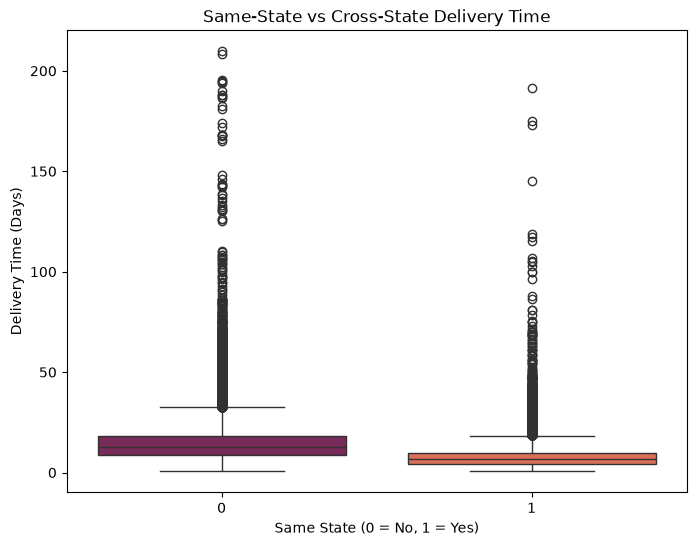

In [40]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=delivery_data,
    x='same_state',
    y='delivery_time_days',
    palette='rocket'
)

plt.title('Same-State vs Cross-State Delivery Time')
plt.xlabel('Same State (0 = No, 1 = Yes)')
plt.ylabel('Delivery Time (Days)')
plt.savefig('../images/same_state_vs_cross_state.png', bbox_inches='tight')
plt.show()

* **Yes, same-state deliveries are noticeably faster. The plot for same-state deliveries (1) shows a lower median delivery time compared to cross-state deliveries (0). and, the tighter and lower box for same-state deliveries means the majority of those orders are completed in fewer days, whereas cross-state deliveries have a much wider range and more extreme delays.**

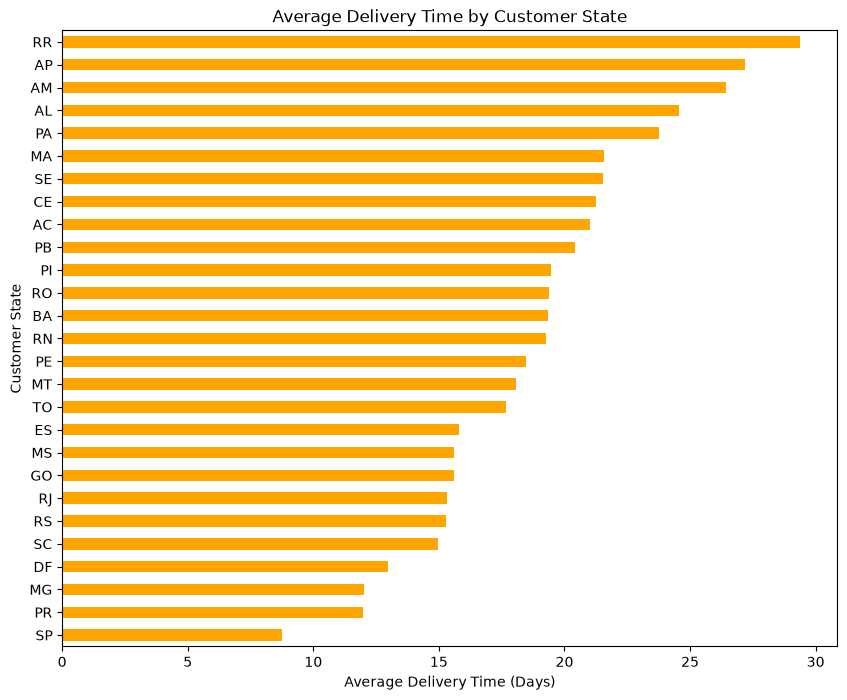

In [41]:
state_delivery = (delivery_data.groupby('customer_state')['delivery_time_days'].mean().sort_values(ascending=False))

plt.figure(figsize=(10, 8))

state_delivery.plot(kind='barh', color='orange')

plt.title('Average Delivery Time by Customer State')
plt.xlabel('Average Delivery Time (Days)')
plt.ylabel('Customer State')
plt.gca().invert_yaxis()
plt.savefig('../images/longest_delivery_time_by_customer_state.png', bbox_inches='tight')
plt.show()

**The states experiencing the longest average delivery times is RR (nearly 30 days), followed by AP and AM (between 25 days to 28 days).**

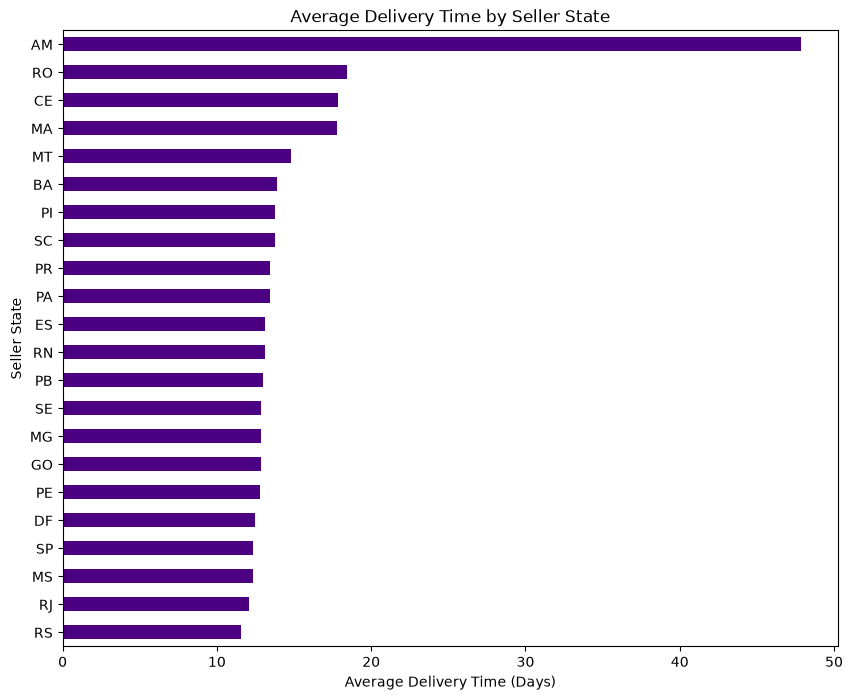

In [42]:
seller_delivery = (delivery_data.groupby('seller_state')['delivery_time_days'].mean().sort_values(ascending=False))

plt.figure(figsize=(10, 8))

seller_delivery.plot(kind='barh', color='indigo')

plt.title('Average Delivery Time by Seller State')
plt.xlabel('Average Delivery Time (Days)')
plt.ylabel('Seller State')
plt.gca().invert_yaxis()
plt.savefig('../images/longest_delivery_time_by_seller_state.png', bbox_inches='tight')
plt.show()

**The seller state with the slowest average delivery time is AM (nearly 50 days on average) and other slowest states are RO, CE, and MA, which all average around 18 days.**

In [43]:
delivery_data.columns

Index(['order_id', 'purchase_dayofweek', 'purchase_month', 'purchase_hour',
       'purchase_is_weekend', 'estimated_delivery_days', 'n_items',
       'n_sellers', 'total_price', 'total_freight', 'avg_price',
       'product_weight_g', 'product_length_cm', 'product_height_cm',
       'product_width_cm', 'payment_installments', 'payment_value',
       'payment_type', 'customer_state', 'seller_state',
       'product_category_name_english', 'distance_km', 'same_state',
       'delivery_time_days'],
      dtype='str')

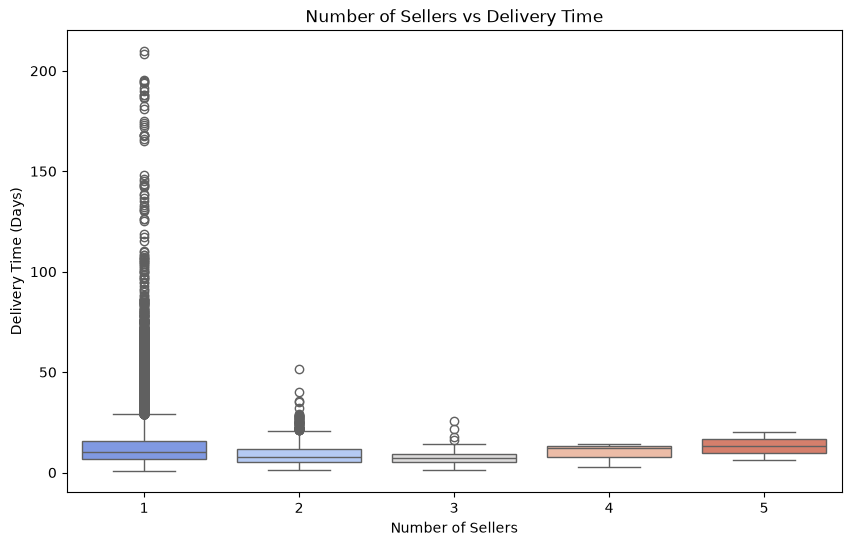

In [44]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=delivery_data,
    x='n_sellers',
    y='delivery_time_days',
    palette='coolwarm'
)

plt.title('Number of Sellers vs Delivery Time')
plt.xlabel('Number of Sellers')
plt.ylabel('Delivery Time (Days)')
plt.savefig('../images/number_of_seller_vs_delivery_time.png', bbox_inches='tight')
plt.show()

**No, Orders involving multiple sellers do not generally take longer to deliver. Instead the most delivery delays are almost from single seller orders and orders with multiple sellers (between 2 to 5) have fewer outliers**

In [45]:
delivery_data['items'] = pd.cut(
    delivery_data['n_items'],
    bins=[0, 1, 3, 6, 21],
    labels=[
        '1 item',
        '2-3 items',
        '4-6 items',
        '7+ items'
    ]
)

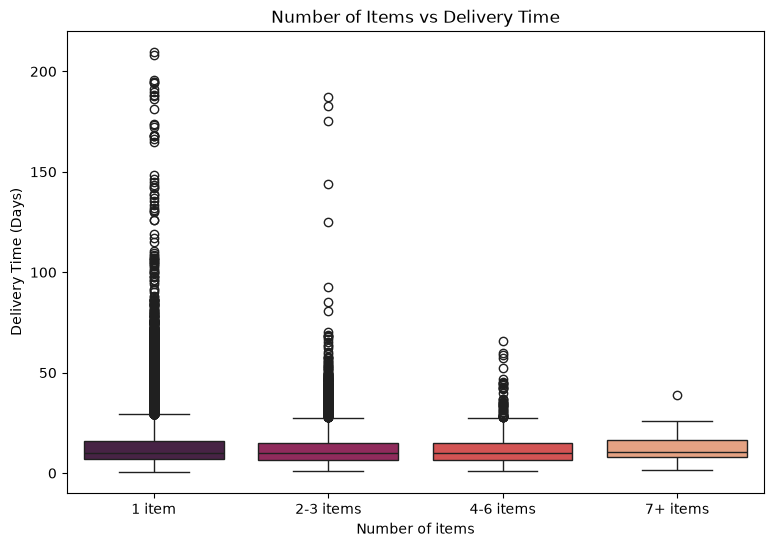

In [46]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=delivery_data,
    x='items',
    y='delivery_time_days',
    palette='rocket'
)

plt.title('Number of Items vs Delivery Time')
plt.xlabel('Number of items')
plt.ylabel('Delivery Time (Days)')
plt.savefig('../images/number_of_items_vs_delivery_time.png', bbox_inches='tight')
plt.show()

**The number of items in an order has no impact on delivery time. The median delivery time remains completely same across all categories, whether a customer orders one item or seven.**

In [47]:
# Dropped after analysis
delivery_data = delivery_data.drop(columns=['items'])

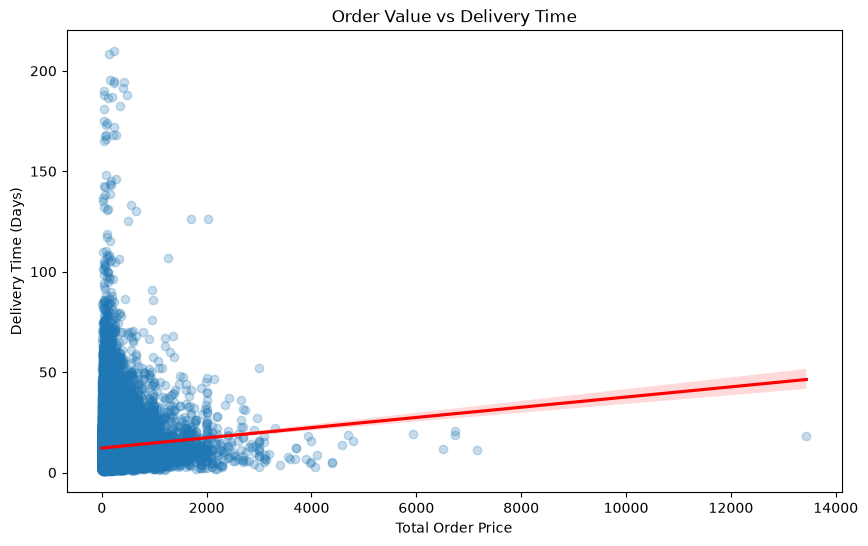

In [48]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=delivery_data,
    x='total_price',
    y='delivery_time_days',
    scatter_kws={'alpha': 0.25},
    line_kws={'color': 'red'}
)

plt.title('Order Value vs Delivery Time')
plt.xlabel('Total Order Price')
plt.ylabel('Delivery Time (Days)')
plt.savefig('../images/order_value_vs_delivery_time.png', bbox_inches='tight')
plt.show()

**Higher order values rarely affect delivery time. while, the most extreme delivery delays happen with much cheaper orders.**

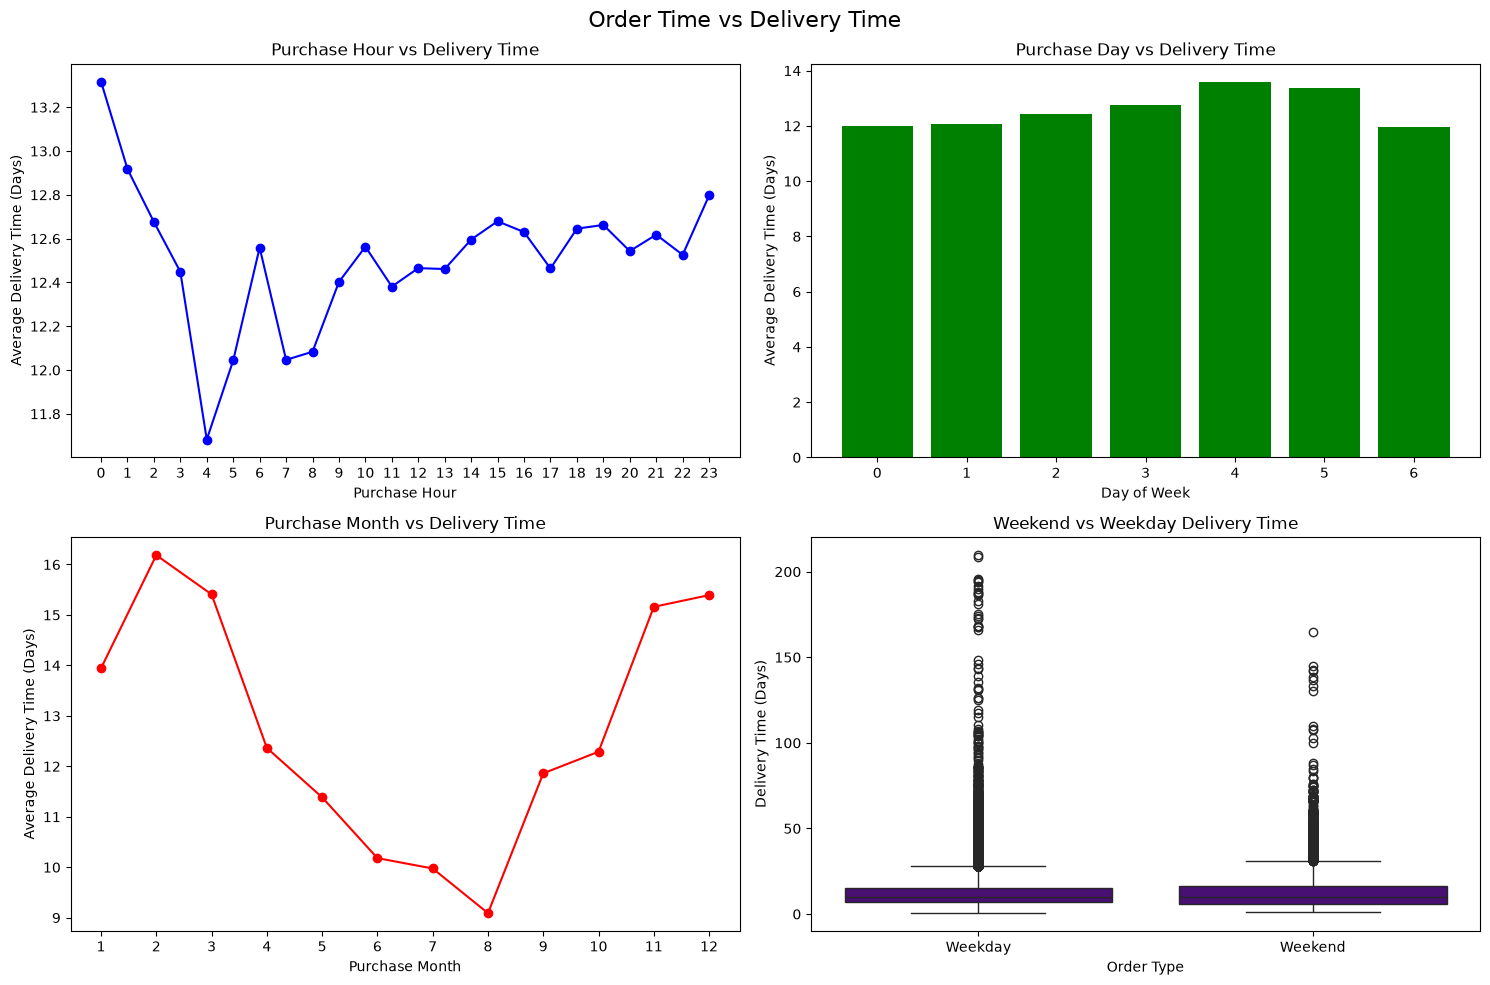

In [49]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Order Time vs Delivery Time', fontsize=16)

# Purchase Hour vs Delivery Time
hour_delivery = delivery_data.groupby('purchase_hour')['delivery_time_days'].mean()
axes[0, 0].plot(hour_delivery.index, hour_delivery.values, marker='o', color='blue')
axes[0, 0].set_title('Purchase Hour vs Delivery Time')
axes[0, 0].set_xlabel('Purchase Hour')
axes[0, 0].set_ylabel('Average Delivery Time (Days)')
axes[0, 0].set_xticks(range(24))

# Purchase Day vs Delivery Time
day_delivery = delivery_data.groupby('purchase_dayofweek')['delivery_time_days'].mean()
axes[0, 1].bar(day_delivery.index, day_delivery.values, color='green')
axes[0, 1].set_title('Purchase Day vs Delivery Time')
axes[0, 1].set_xlabel('Day of Week')
axes[0, 1].set_ylabel('Average Delivery Time (Days)')

# Purchase Month vs Delivery Time 
month_delivery = delivery_data.groupby('purchase_month')['delivery_time_days'].mean()
axes[1, 0].plot(month_delivery.index, month_delivery.values, marker='o', color='red')
axes[1, 0].set_title('Purchase Month vs Delivery Time')
axes[1, 0].set_xlabel('Purchase Month')
axes[1, 0].set_ylabel('Average Delivery Time (Days)')
axes[1, 0].set_xticks(sorted(delivery_data['purchase_month'].unique()))

# Weekend vs Weekday Delivery Time 
sns.boxplot(data=delivery_data, x='purchase_is_weekend', y='delivery_time_days', ax=axes[1, 1], color='indigo')
axes[1, 1].set_title('Weekend vs Weekday Delivery Time')
axes[1, 1].set_xlabel('Order Type')
axes[1, 1].set_ylabel('Delivery Time (Days)')
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(['Weekday', 'Weekend'])

plt.tight_layout()
plt.savefig('../images/order_time_vs_delivery_time.png', bbox_inches='tight')
plt.show()

* **Purchase month: average delivery times changes throughout the year, peaking at over 16 days at month 2 and dropped to a low of about 9 days in month 8**
* **Hour of day: orders placed at hour 4 shows the fastest average delivery times (under 12 days).**
* **Day of the week: day 4 and day 5 shows higher average delivery times compared to the rest of the week.**
* **weekend vs weekday: The median delivery times are nearly identical, and weekday orders have extreme outliers.**

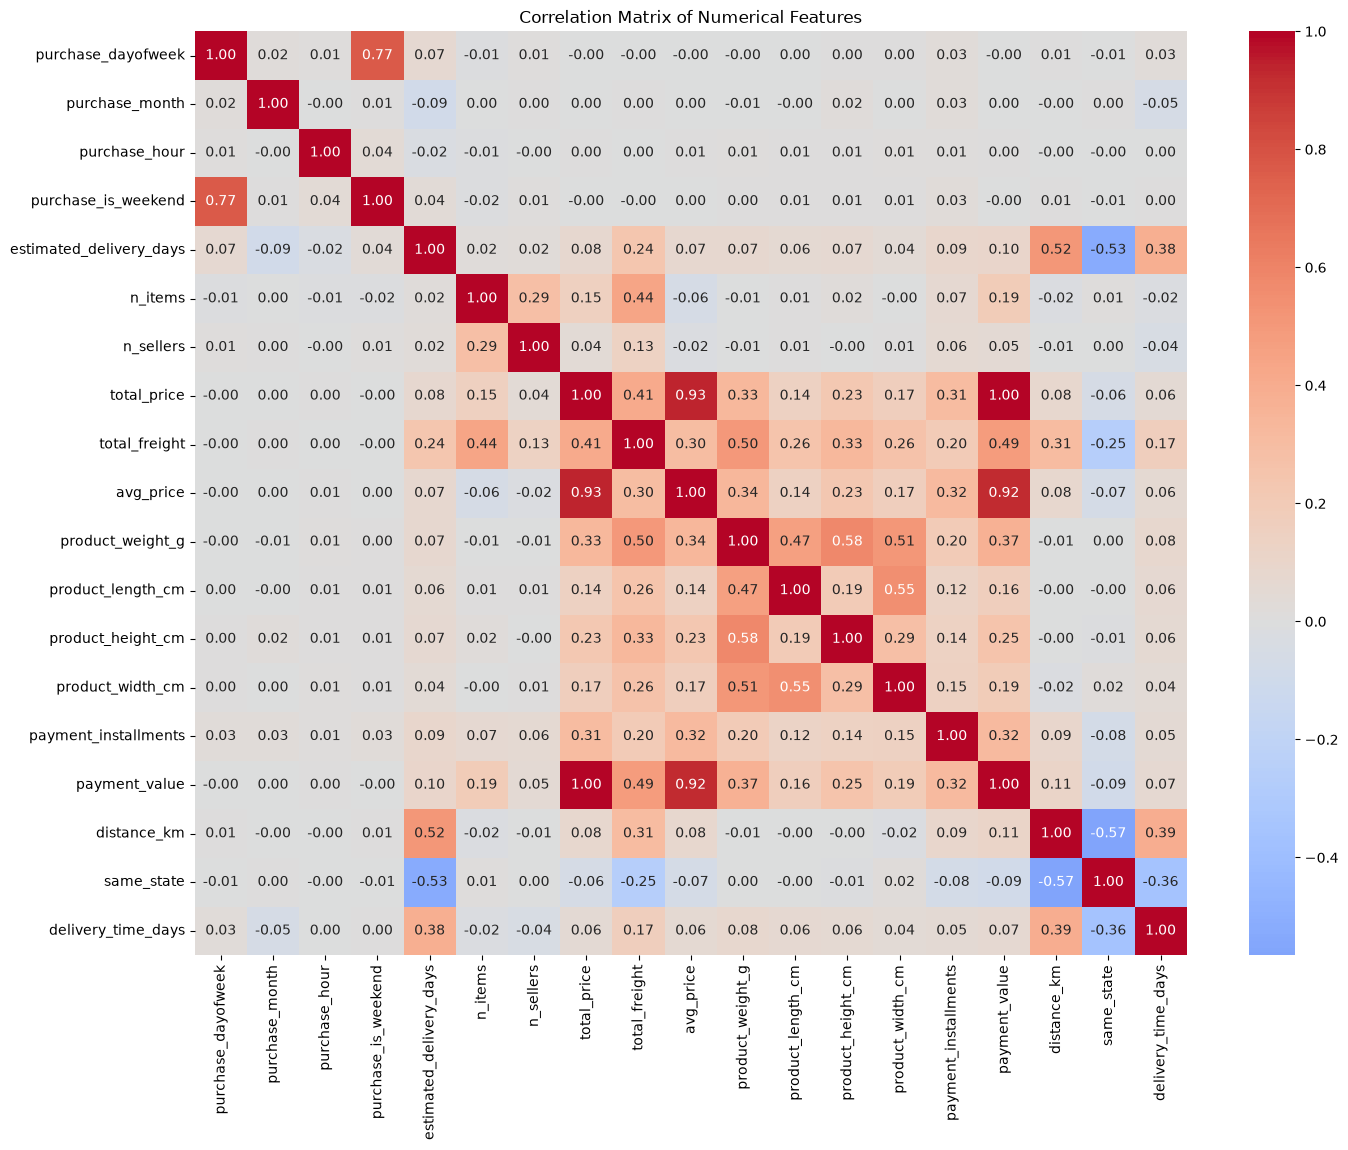

In [50]:
plt.figure(figsize=(16, 12))
corr = delivery_data.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Numerical Features')
plt.savefig('../images/correlation_heatmap.png', bbox_inches='tight')
plt.show()

**distance_km, estimated_delivery_days, total_freight are positively correlated (means as distance_km, estimated_delivery_days, total_freight increases delivery time increases) while same_state is negatively correlated (means as state is same_state delivery time will decrease) so, these are the helpful predictors to predicts delivery time**